## Read embeddings

In [1]:
import pandas as pd
MODELS_DESCRIPTIONS = {
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
    "mix_of_alleles_balanced":
    {
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "path": "experiment_results/alleles_with_groups_balanced/",
        "states": 25,
        "params_string": "5-min_iters",
        "target_lengths": [9, 10]
    }

}
selected_model = MODELS_DESCRIPTIONS["mix_of_alleles"]


In [2]:

selected_alleles = selected_model['alleles']
states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = 0
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [3]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [4]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [5]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
CPU times: total: 24.1 s
Wall time: 27 s


# Scanpy

In [6]:
target_df = per_model_type_train_embeddings['bw']

In [7]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [8]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,1525,1526,1527,1528,1529,1530,1531,1532,allele,peptide
SFDIQLTSV,-0.362316,-0.420739,-0.368622,-0.427045,-0.356662,-0.415085,-0.363203,-0.335945,-0.421626,-0.391011,...,-0.534056,-0.518725,-0.527047,-0.479612,-0.522206,-0.497078,-0.518408,-0.537497,HLA-A*01:01,SFDIQLTSV
TTEILRSML,-0.348627,-0.411487,-0.352085,-0.414944,-0.363734,-0.426593,-0.367426,-0.328373,-0.430286,-0.387620,...,-0.488532,-0.496115,-0.496091,-0.479122,-0.490204,-0.476559,-0.492915,-0.505883,HLA-A*01:01,TTEILRSML
ALNDTWKMEK,-0.470067,-0.428844,-0.472029,-0.430806,-0.472750,-0.431527,-0.474947,-0.419987,-0.433724,-0.381134,...,-0.508289,-0.523257,-0.530021,-0.531189,-0.509961,-0.539256,-0.516521,-0.527336,HLA-A*03:01,ALNDTWKMEK
ALAAAAAAAK,-0.397731,-0.362144,-0.398176,-0.362588,-0.399633,-0.364045,-0.400312,-0.361934,-0.364725,-0.328392,...,-0.500674,-0.497479,-0.509922,-0.457513,-0.498119,-0.476667,-0.497820,-0.498484,HLA-A*03:01,ALAAAAAAAK
LYDKDAVYV,-0.380560,-0.466002,-0.382958,-0.468399,-0.382461,-0.467903,-0.385094,-0.351003,-0.470536,-0.431534,...,-0.531042,-0.529772,-0.532119,-0.473593,-0.530412,-0.482974,-0.523481,-0.543206,HLA-A*01:01,LYDKDAVYV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FIFQSSMTK,-0.383718,-0.380586,-0.388251,-0.385119,-0.382427,-0.379294,-0.387194,-0.396409,-0.384062,-0.393456,...,-0.503212,-0.490136,-0.461676,-0.476887,-0.494630,-0.485735,-0.496184,-0.467146,HLA-A*03:01,FIFQSSMTK
QLYKEQLAK,-0.367031,-0.314063,-0.364880,-0.311912,-0.368180,-0.315212,-0.366264,-0.389512,-0.313296,-0.339588,...,-0.532753,-0.524032,-0.499716,-0.489601,-0.530198,-0.487154,-0.537019,-0.491646,HLA-A*03:01,QLYKEQLAK
LLNRPLWAK,-0.367695,-0.357004,-0.375702,-0.365012,-0.362041,-0.351350,-0.370284,-0.384747,-0.359593,-0.374671,...,-0.539034,-0.532999,-0.520538,-0.483386,-0.536479,-0.488796,-0.535443,-0.523010,HLA-A*03:01,LLNRPLWAK
KVPVVLLKK,-0.368140,-0.313210,-0.367818,-0.312888,-0.362487,-0.307557,-0.362399,-0.404682,-0.307469,-0.352909,...,-0.507186,-0.513622,-0.511201,-0.518475,-0.517103,-0.503557,-0.523924,-0.509615,HLA-A*03:01,KVPVVLLKK


In [9]:
import scanpy as sc
import anndata as ad
import numpy as np

In [10]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)

In [11]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

d:\tools\python\anaconda\envs\biopython\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [12]:
adata

AnnData object with n_obs × n_vars = 13336 × 1533
    obs: 'peptide', 'allele', 'length'
    var: 'path'

In [13]:
adata.obs

,peptide,allele,length
0,SFDIQLTSV,HLA-A*01:01,9
1,TTEILRSML,HLA-A*01:01,9
2,ALNDTWKMEK,HLA-A*03:01,10
3,ALAAAAAAAK,HLA-A*03:01,10
4,LYDKDAVYV,HLA-A*01:01,9
...,...,...,...
13331,FIFQSSMTK,HLA-A*03:01,9
13332,QLYKEQLAK,HLA-A*03:01,9
13333,LLNRPLWAK,HLA-A*03:01,9
13334,KVPVVLLKK,HLA-A*03:01,9


In [14]:
adata.var

,path
0,0
1,1
2,2
3,3
4,4
...,...
1528,1528
1529,1529
1530,1530
1531,1531


In [15]:
adata.X

array([[0.69606262, 0.65656169, 0.69168698, ..., 0.60830527, 0.59546754,
        0.58420881],
       [0.70565638, 0.66266447, 0.70322058, ..., 0.62091635, 0.61084341,
        0.60297297],
       [0.62496022, 0.65126127, 0.62373541, ..., 0.58318196, 0.59659274,
        0.59017493],
       ...,
       [0.69232856, 0.69976978, 0.68680665, ..., 0.61336437, 0.58541007,
        0.59273375],
       [0.69202013, 0.73109607, 0.69224324, ..., 0.6043771 , 0.59219231,
        0.60072694],
       [0.72903641, 0.69121581, 0.72871235, ..., 0.61707753, 0.58743029,
        0.5977181 ]])

## 1. Normalize

In [16]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [17]:
adata.X

array([[0.52626611, 0.5027709 , 0.5236905 , ..., 0.47329798, 0.46530873,
        0.45824922],
       [0.53164544, 0.50620139, 0.53022102, ..., 0.48085798, 0.47464576,
        0.46976486],
       [0.50026858, 0.51669863, 0.49949684, ..., 0.47360207, 0.48223973,
        0.47811543],
       ...,
       [0.52452351, 0.5289009 , 0.52126276, ..., 0.47685167, 0.45941538,
        0.46401295],
       [0.51991178, 0.5425467 , 0.52004249, ..., 0.46720006, 0.45964664,
        0.46494328],
       [0.53636279, 0.51459168, 0.53617825, ..., 0.47048824, 0.45229243,
        0.45864409]])

## 2. Highly variable features
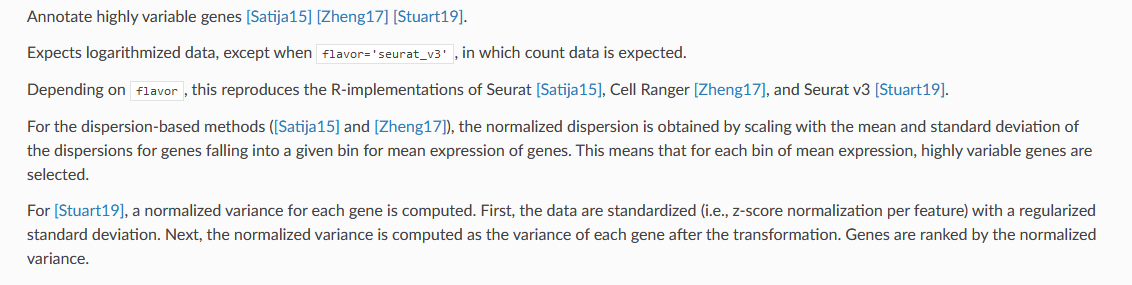
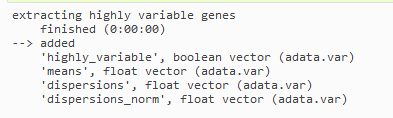
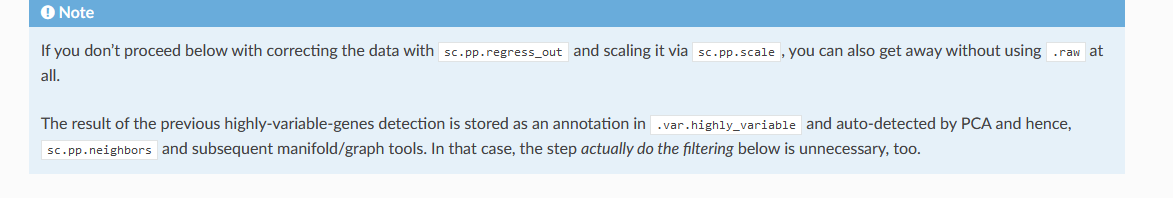



<AxesSubplot:xlabel='mean expressions of genes', ylabel='dispersions of genes (not normalized)'>

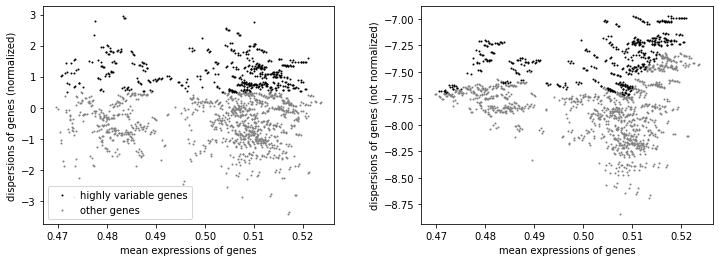

In [18]:
import matplotlib.pyplot as plt
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

## 3. PCA

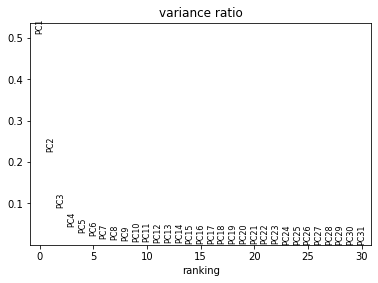

In [19]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## 4. Neighborhood graph and umap

In [20]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

### Select metric

In [21]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

metric: sokalmichener (0, 0)
metric: sokalsneath (0, 1)
metric: yule (0, 2)
metric: cosine (0, 3)
metric: euclidean (0, 4)
metric: l1 (1, 0)
metric: l2 (1, 1)
metric: manhattan (1, 2)
metric: braycurtis (1, 3)
metric: canberra (1, 4)
metric: chebyshev (2, 0)
metric: correlation (2, 1)
metric: dice (2, 2)
metric: hamming (2, 3)
metric: jaccard (2, 4)
metric: kulsinski (3, 0)
metric: mahalanobis (3, 1)
metric: minkowski (3, 2)
metric: rogerstanimoto (3, 3)
metric: russellrao (3, 4)


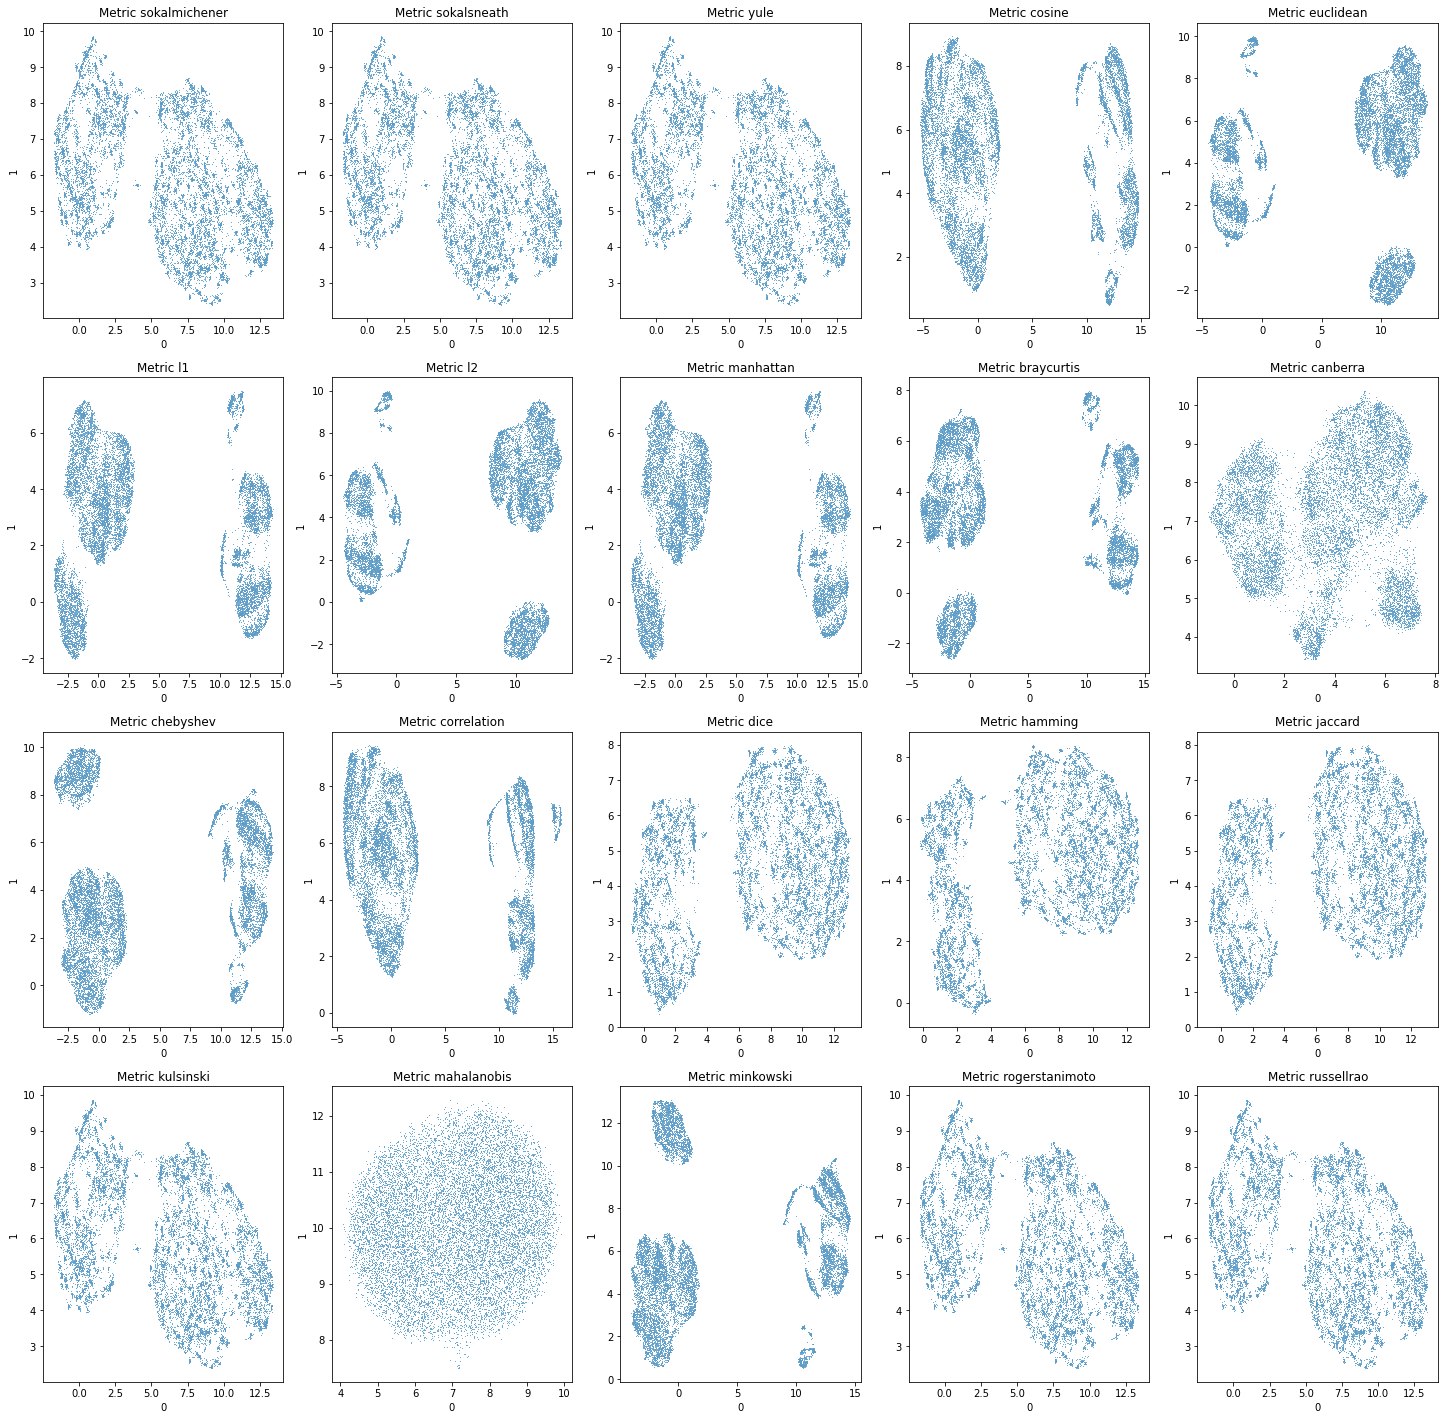

In [22]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [23]:
principal_components = range(5, 30, 5)

In [24]:
list(principal_components)

[5, 10, 15, 20, 25]

In [25]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


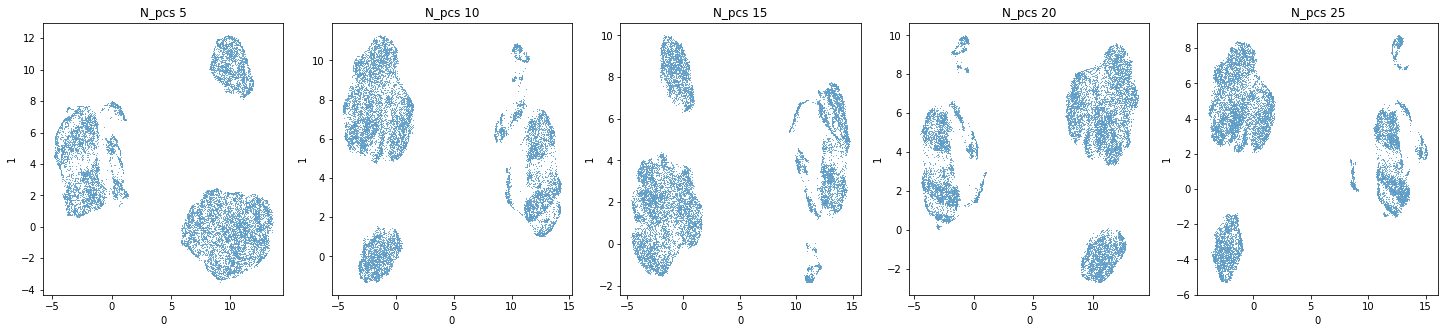

In [26]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [27]:
num_neighbors = range(5, 55, 5)

In [28]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


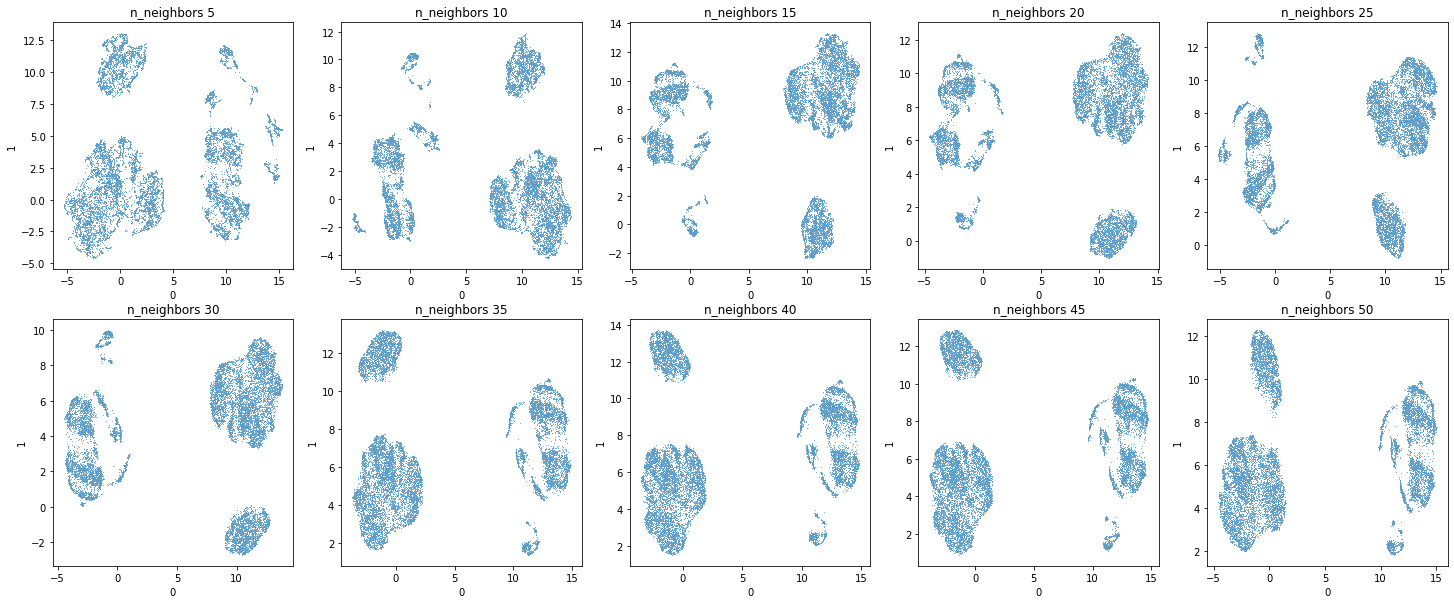

In [29]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [30]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


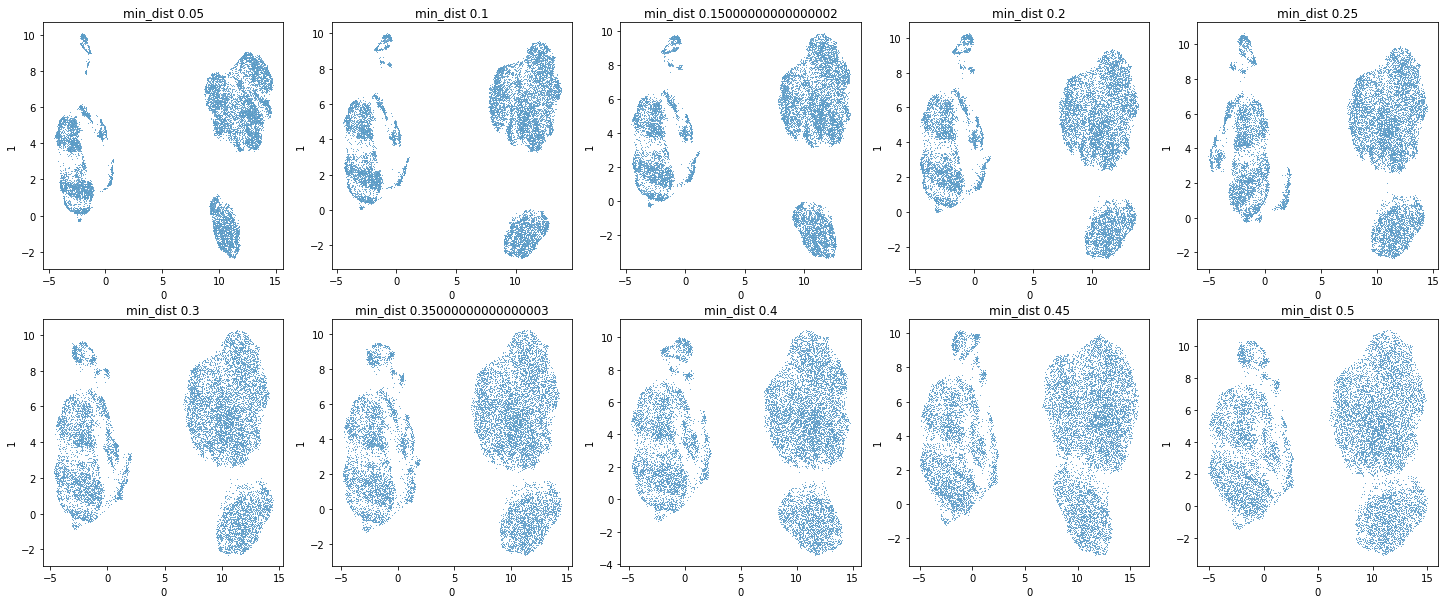

In [31]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")

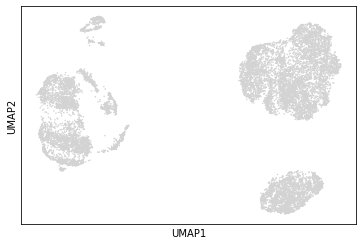

In [32]:
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric="euclidean")
sc.tl.umap(adata, min_dist=0.1)
sc.pl.umap(adata)

## 5.  Cell clusters

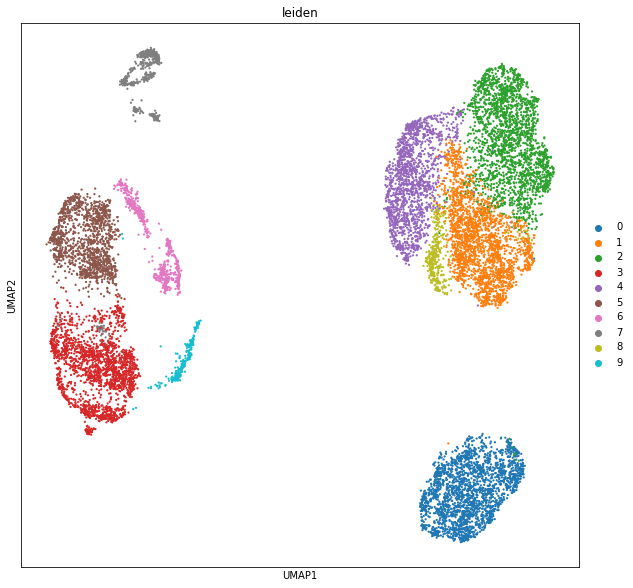

In [41]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.leiden(adata, resolution=0.7)
    sc.tl.louvain(adata, resolution=0.7)
    sc.pl.umap(adata, color='leiden', s=20)
    # sc.pl.umap(adata, color='louvain', s=20)

<AxesSubplot:xlabel='0', ylabel='1'>

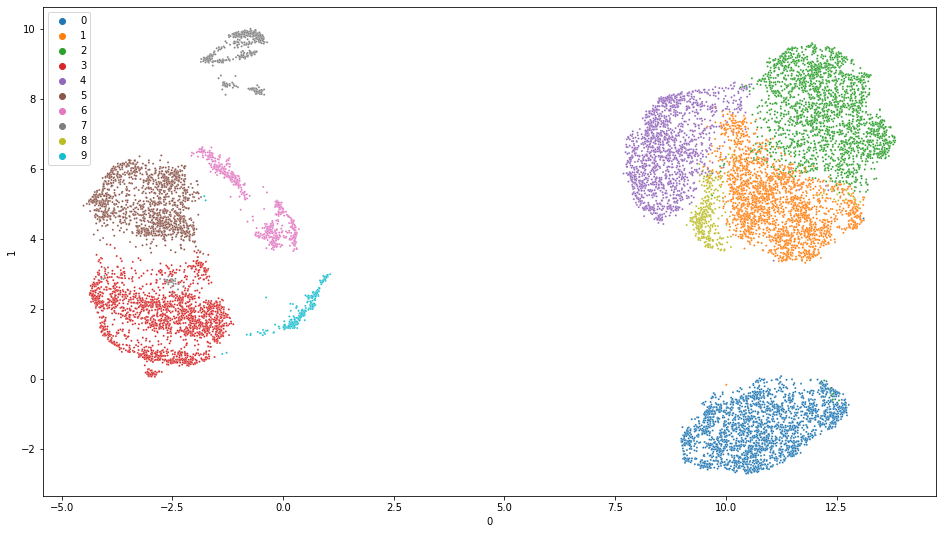

In [34]:
plt.figure(figsize=(16,9))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=4, hue=adata.obs['leiden'].values)

## 6. Color by allele

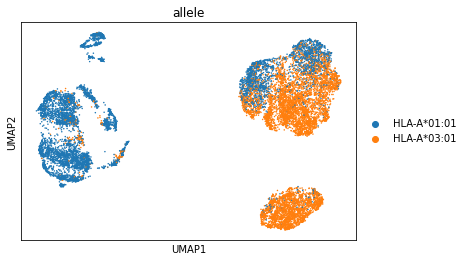

In [35]:
sc.pl.umap(adata, color="allele")

<AxesSubplot:xlabel='0', ylabel='1'>

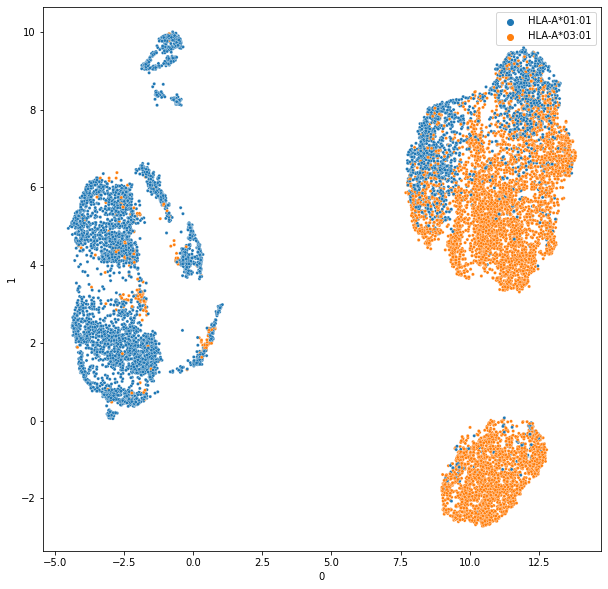

In [36]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata.obs['allele'].values)

## 7. Plot cluster motifs

In [37]:
peptides_df = adata.obs.copy()

In [38]:
import logomaker
def make_logo(df, length=9, cluster_num=0):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = dict(df['allele'].value_counts())
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"Cluster {cluster_num} Allele counts: {counts}")

In [39]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden' ):
    unique_clusters = peptides_df[cluster_column].unique()
    for cluster_num in unique_clusters:
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df, cluster_num=cluster_num)

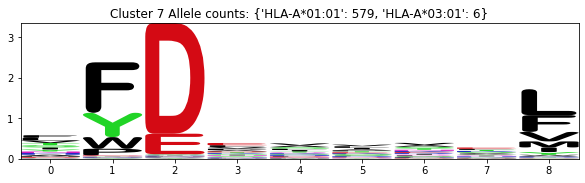

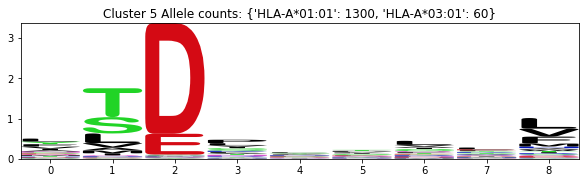

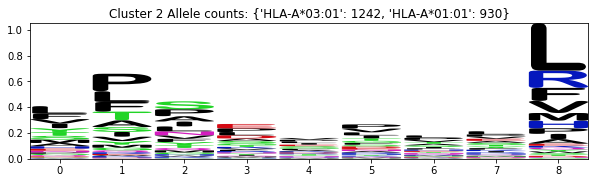

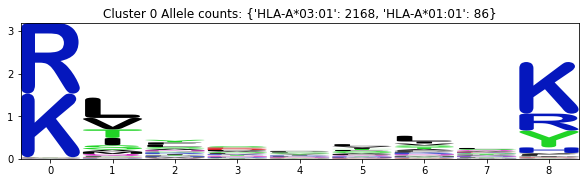

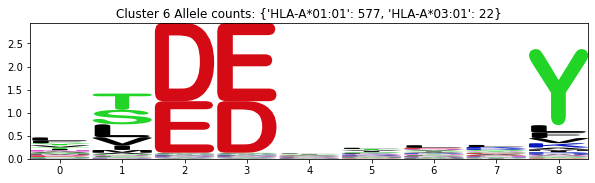

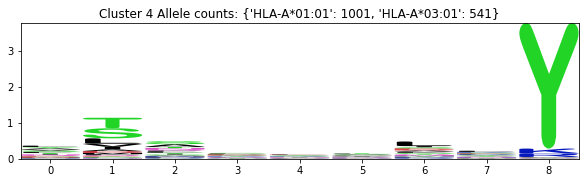

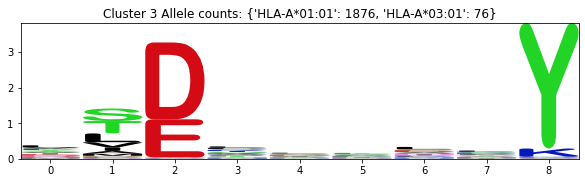

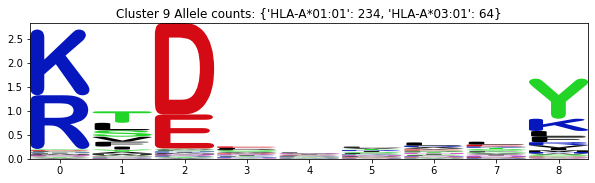

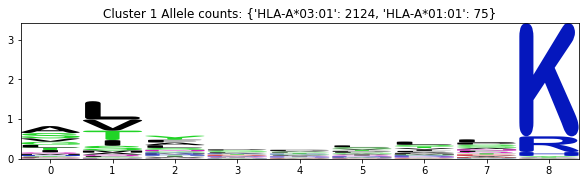

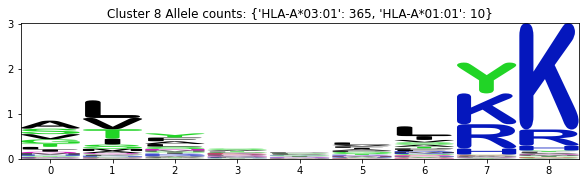

In [40]:
plot_all_cluster_motifs(peptides_df)